# 02 · Análisis descriptivo y visualización

**Pregunta de negocio:** ¿qué características del cliente, del contacto y del contexto económico se asocian a que el cliente **suscriba el depósito a plazo** (`y = yes`)?

Estructura:
1. Variable objetivo
2. Estadística descriptiva de las variables numéricas
3. Perfil del cliente (variables sociodemográficas)
4. Estrategia de contacto (canal, insistencia, historial)
5. Duración de la llamada
6. Contexto macroeconómico y correlaciones
7. Datos de cliente del Excel (ingresos, hijos, web, año de alta)
8. Cruces de variables
9. Ranking de factores (chi-cuadrado y V de Cramér)
10. Conclusiones



In [2]:
# Preparación para Google Colab (en local no hace nada)
import os
import sys
import zipfile

if "google.colab" in sys.modules:
    proyecto = "/content/eda-bank-marketing"
    if not os.path.exists(proyecto):
        from google.colab import files
        print("Selecciona el archivo eda-bank-marketing.zip")
        subido = files.upload()
        zipfile.ZipFile(next(iter(subido)), "r").extractall("/content")
    os.chdir(proyecto + "/notebooks")
    print("Listo. Carpeta de trabajo:", os.getcwd())

Listo. Carpeta de trabajo: /content/eda-bank-marketing/notebooks


In [3]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sys.path.append(str(Path.cwd().parent / "src"))
import funciones as fn

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
fn.estilo_graficos()

df = fn.cargar_procesado()
MEDIA = df["y_num"].mean() * 100
print(df.shape)
df.head(3)

(43000, 41)


,age,job,marital,education,default,housing,loan,contact,duration,campaign,pdays,previous,poutcome,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,y,date,...,longitude,id_cliente,contact_year,contact_month,age_imputada,contactado_antes,y_num,duration_min,grupo_edad,grupo_campaign,income,kidhome,teenhome,dt_customer,num_web_visits_month,anio_alta,hijos_total,tiene_hijos,grupo_ingresos,grupo_web
0,45,housemaid,married,basic_4y,0,0,0,telephone,261,1,NaN,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,2019-08-02,...,-71.233,089b39d8-e4d0-461b-87d4-814d71e0e079,2019,8,1,0,0,4.35,45-54,1,161770,1,0,2012-04-04,29,2012,1,1,Q4 alto,>20
1,57,services,married,high_school,<NA>,0,0,telephone,149,1,NaN,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,2016-09-14,...,-83.923,e9d37224-cb6f-4942-98d7-46672963d097,2016,9,0,0,0,2.48,55-64,1,85477,1,1,2012-12-30,7,2012,2,1,Q2,6-10
2,37,services,married,high_school,0,1,0,telephone,226,1,NaN,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,2019-02-15,...,-94.847,3f9f49b5-e410-4948-bf6e-f9244f04918b,2019,2,0,0,0,3.77,35-44,1,147233,1,1,2012-02-02,5,2012,2,1,Q4 alto,0-5


## 1. Variable objetivo

In [4]:
resumen_y = df["y"].value_counts().to_frame("clientes").assign(pct=lambda t: (t["clientes"] / t["clientes"].sum() * 100).round(2))
resumen_y

,clientes,pct
y,,
no,38156,88.73
yes,4844,11.27


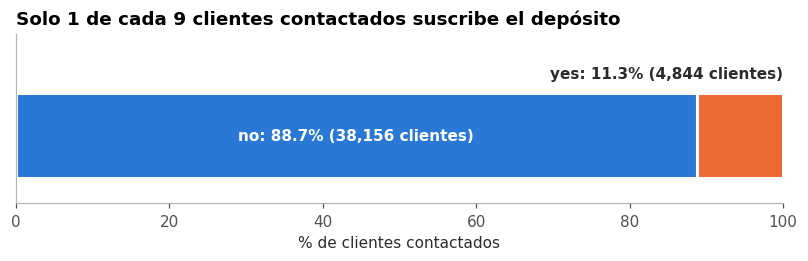

In [5]:
fig, ax = plt.subplots(figsize=(9, 2))
izq = 0
for etiqueta, fila in resumen_y.iterrows():
    ax.barh(0, fila["pct"], left=izq, color=fn.COLORES_Y[etiqueta], height=0.5, edgecolor="white", linewidth=2)
    texto = f"{etiqueta}: {fila['pct']:.1f}% ({int(fila['clientes']):,} clientes)"
    if fila["pct"] > 30:   # etiqueta dentro de la barra grande
        ax.text(izq + fila["pct"] / 2, 0, texto, ha="center", va="center", color="white", fontweight="bold")
    else:                  # etiqueta encima de la barra pequeña
        ax.text(izq + fila["pct"], 0.32, texto, ha="right", va="bottom", color="#2b2b29", fontweight="bold")
    izq += fila["pct"]
ax.set_ylim(-0.4, 0.6)
ax.set_xlim(0, 100); ax.set_yticks([]); ax.grid(False); ax.set_xlabel("% de clientes contactados")
ax.set_title("Solo 1 de cada 9 clientes contactados suscribe el depósito")
fn.guardar(fig, "01_variable_objetivo"); plt.show()

El dataset está **muy desbalanceado**: solo el **11,3 %** de los contactos acaba en suscripción. Por eso, en todo el análisis se compara la **tasa de conversión** de cada grupo con esta media global (línea discontinua en los gráficos) en lugar de mirar recuentos absolutos.

## 2. Estadística descriptiva de las variables numéricas

In [6]:
num_cliente = ["age", "duration", "campaign", "previous", "income", "num_web_visits_month", "hijos_total"]
num_macro = fn.COLS_MACRO
fn.estadisticos(df, num_cliente + num_macro)

,count,mean,median,std,min,max,skew,q1,q3,iqr,cv_%
age,43000.0,39.81,38.00,9.96,17.00,98.00,0.88,33.00,46.00,13.00,25.02
duration,43000.0,257.74,179.00,258.67,0.00,4918.00,3.32,102.00,319.00,217.00,100.36
campaign,43000.0,2.57,2.00,2.77,1.00,56.00,4.77,1.00,3.00,2.00,107.99
previous,43000.0,0.17,0.00,0.50,0.00,7.00,3.83,0.00,0.00,0.00,285.80
income,43000.0,93241.20,93050.50,50498.32,5841.00,180802.00,0.00,49610.00,136744.50,87134.50,54.16
num_web_visits_month,43000.0,16.59,17.00,9.24,1.00,32.00,-0.01,9.00,25.00,16.00,55.69
hijos_total,43000.0,2.00,2.00,1.15,0.00,4.00,-0.01,1.00,3.00,2.00,57.56
emp_var_rate,43000.0,0.08,1.10,1.57,-3.40,1.40,-0.72,-1.80,1.40,3.20,2040.63
cons_price_idx,43000.0,93.57,93.75,0.58,92.20,94.77,-0.23,93.08,93.99,0.92,0.62
cons_conf_idx,43000.0,-40.51,-41.80,4.64,-50.80,-26.90,0.31,-42.70,-36.40,6.30,-11.45


**Lectura:**
- **`age`**: media 39,8 y mediana 38 → ligera asimetría a la derecha (cola de clientes mayores). El 50 % central está entre 32 y 46 años.
- **`duration`** y **`campaign`**: muy asimétricas (skew > 3) y con coeficiente de variación > 100 %. La media no es representativa: se usará la **mediana** (179 s y 2 contactos).
- **`previous`**: la mediana es 0; la gran mayoría nunca había sido contactada.
- **`income`** y **`num_web_visits_month`**: distribuciones casi simétricas (media ≈ mediana) y muy planas, típicas de una distribución **uniforme**.
- **`emp_var_rate`**: su CV no es interpretable porque la media es casi 0 (toma valores positivos y negativos).
- **`euribor3m`**: media 3,6 vs mediana 4,86 → distribución **bimodal** (periodos de tipos altos ~5 % y bajos ~1 %).

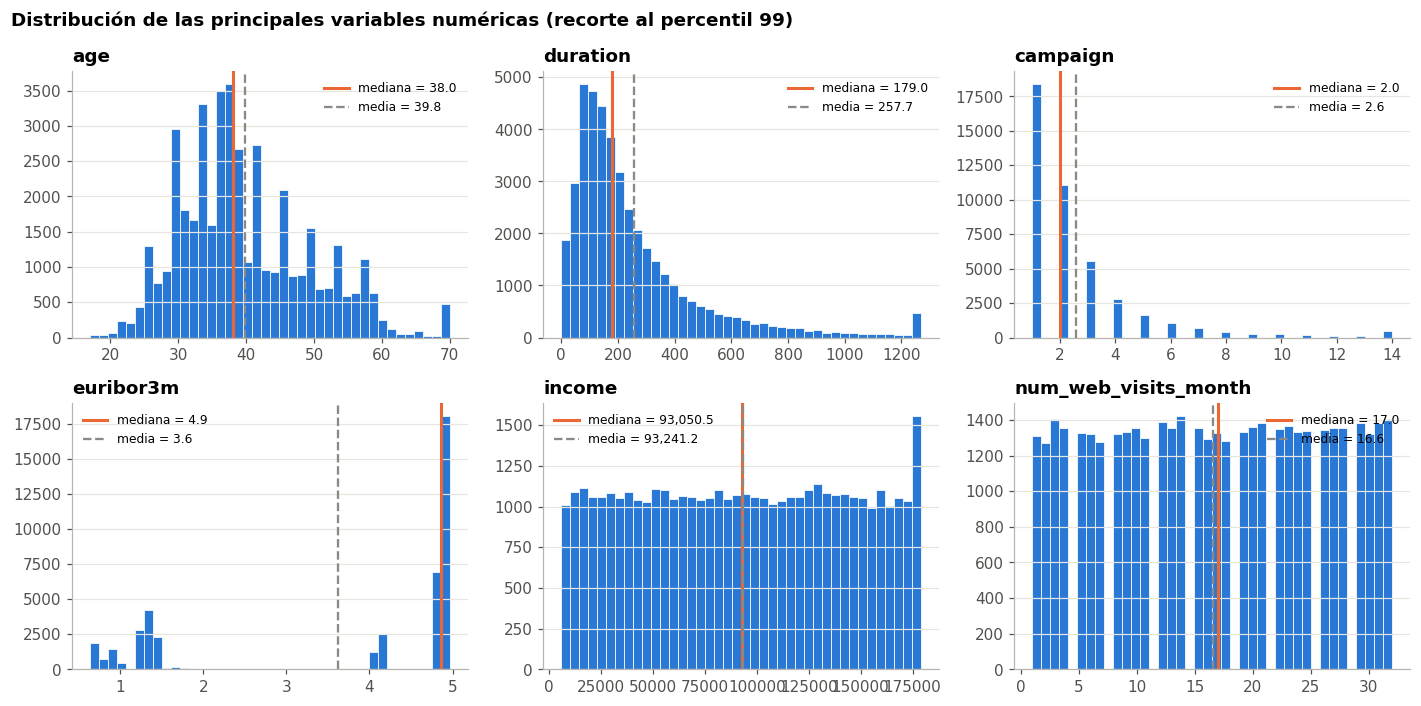

In [7]:
cols_hist = ["age", "duration", "campaign", "euribor3m", "income", "num_web_visits_month"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, col in zip(axes.flat, cols_hist):
    datos = df[col].clip(upper=df[col].quantile(0.99))  # recorte visual del 1% extremo
    ax.hist(datos, bins=40, color=fn.COLOR_PRINCIPAL, edgecolor="white", linewidth=0.5)
    ax.axvline(df[col].median(), color=fn.COLOR_SECUNDARIO, lw=2, label=f"mediana = {df[col].median():,.1f}")
    ax.axvline(df[col].mean(), color=fn.COLOR_NEUTRO, lw=1.5, ls="--", label=f"media = {df[col].mean():,.1f}")
    ax.set_title(col); ax.legend(fontsize=8)
fig.suptitle("Distribución de las principales variables numéricas (recorte al percentil 99)", fontweight="bold", x=0.01, ha="left")
fig.tight_layout(); fn.guardar(fig, "02_distribuciones_numericas"); plt.show()

### Comparación entre quienes suscriben y quienes no

In [8]:
df.groupby("y", observed=True)[num_cliente + ["euribor3m", "nr_employed"]].agg(["mean", "median"]).T.round(2)

y                                  no       yes
age                  mean       39.70     40.68
                     median     38.00     37.00
duration             mean      220.43    551.62
                     median    163.00    449.00
campaign             mean        2.63      2.05
                     median      2.00      2.00
previous             mean        0.13      0.50
                     median      0.00      0.00
income               mean    93324.60  92584.30
                     median  93206.50  92144.50
num_web_visits_month mean       16.59     16.60
                     median     17.00     17.00
hijos_total          mean        2.00      2.00
                     median      2.00      2.00
euribor3m            mean        3.81      2.11
                     median      4.86      1.27
nr_employed          mean     5176.03   5094.54
                     median   5195.80   5099.10

Las diferencias más claras están en **`duration`** (mediana 449 s vs 163 s), **`previous`**, **`euribor3m`** (1,27 vs 4,86) y **`nr_employed`**. En cambio, **edad, ingresos, visitas web e hijos son prácticamente iguales** en ambos grupos.

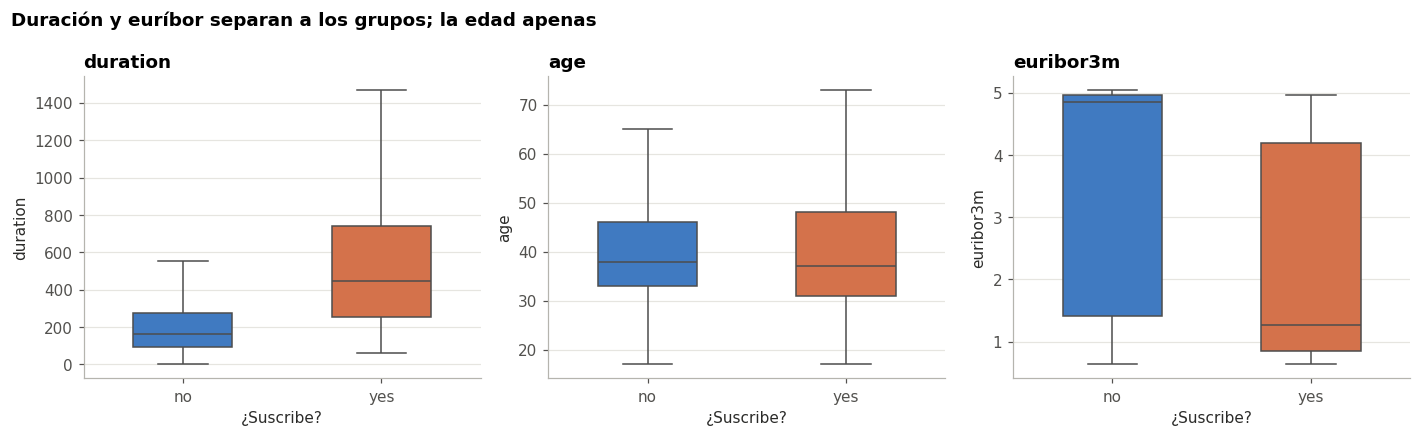

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col in zip(axes, ["duration", "age", "euribor3m"]):
    sns.boxplot(data=df, x="y", y=col, hue="y", palette=fn.COLORES_Y, ax=ax, legend=False,
                showfliers=False, width=0.5, order=["no", "yes"])
    ax.set_title(col); ax.set_xlabel("¿Suscribe?")
fig.suptitle("Duración y euríbor separan a los grupos; la edad apenas", fontweight="bold", x=0.01, ha="left")
fig.tight_layout(); fn.guardar(fig, "03_boxplots_por_y"); plt.show()

## 3. Perfil del cliente

In [10]:
# Frecuencias de las categóricas en una sola tabla (comprensión de diccionario + concat)
frecuencias = {col: df[col].value_counts(normalize=True).mul(100).round(1) for col in ["job", "marital", "education", "grupo_edad"]}
pd.concat(frecuencias, names=["variable", "categoria"]).to_frame("% clientes")

% clientes
variable   categoria                      
job        admin                      25.3
           blue-collar                22.5
           technician                 16.3
           services                    9.7
           management                  7.1
           retired                     4.2
           entrepreneur                3.5
           self-employed               3.5
           housemaid                   2.6
           unemployed                  2.5
           student                     2.1
           unknown                     0.8
marital    married                    60.5
           single                     28.2
           divorced                   11.2
           unknown                     0.2
education  university_degree          29.6
           high_school                23.1
           basic_9y                   14.7
           professional_course        12.7
           basic_4y                   10.1
           basic_6y                    5.5
           unknown                     4.2
           illiterate                  0.0
grupo_edad 35-44                      39.7
           25-34                      29.7
           45-54                      18.9
           55-64                       8.0
           <25                         2.3
           65+                         1.4

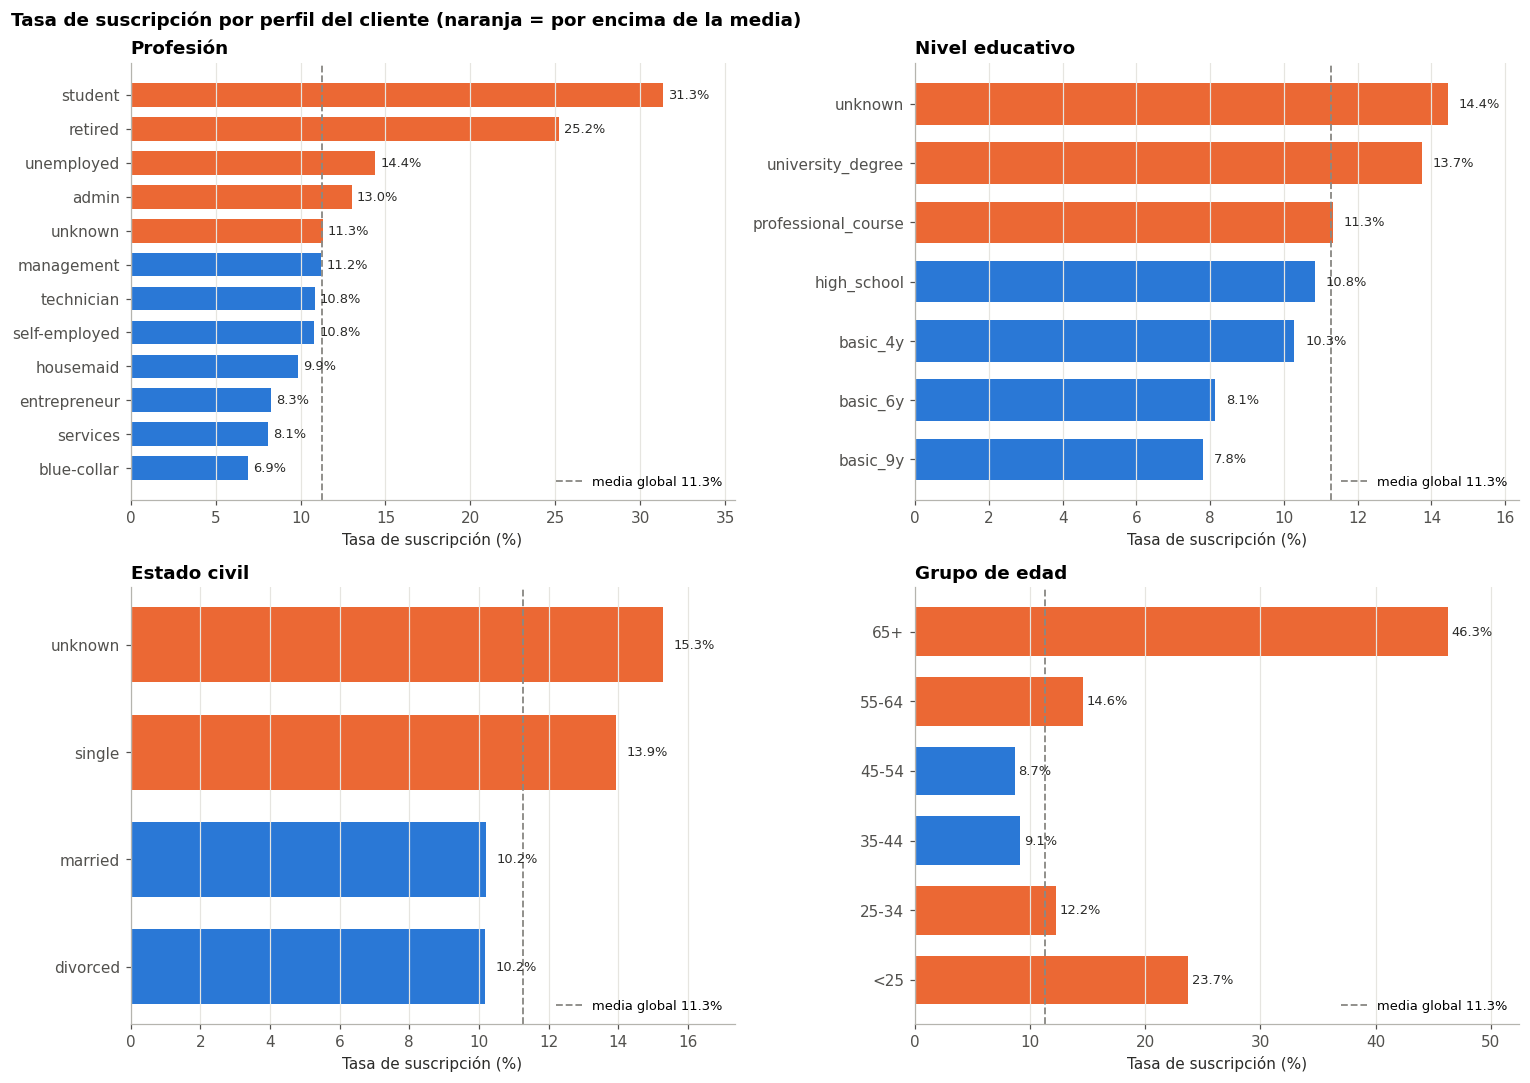

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
vars_perfil = {"job": "Profesión", "education": "Nivel educativo", "marital": "Estado civil", "grupo_edad": "Grupo de edad"}
for ax, (col, titulo) in zip(axes.flat, vars_perfil.items()):
    tabla = fn.tasa_conversion(df, col, min_n=50)  # se excluyen grupos con < 50 clientes
    fn.barras_conversion(tabla, titulo, MEDIA, ax=ax, ordenar=col not in ["grupo_edad"])
fig.suptitle("Tasa de suscripción por perfil del cliente (naranja = por encima de la media)", fontweight="bold", x=0.01, ha="left")
fig.tight_layout(); fn.guardar(fig, "04_conversion_perfil"); plt.show()

In [12]:
fn.tasa_conversion(df, "grupo_edad")

,contactos,suscripciones,tasa
grupo_edad,,,
<25,994,236,23.74
25-34,12768,1559,12.21
35-44,17057,1557,9.13
45-54,8112,702,8.65
55-64,3453,505,14.62
65+,616,285,46.27


**Hallazgos del perfil:**
- **La edad tiene forma de U**: los **mayores de 65 (46 %)** y los **menores de 25 (24 %)** convierten muchísimo más que la franja 35-54 (~9 %).
- En coherencia, **`student` (31 %)** y **`retired` (25 %)** son las profesiones con más éxito; **`blue-collar` (6,9 %)**, `services` y `entrepreneur` las que menos.
- Los **solteros** convierten más (13,9 %) que casados y divorciados (~10,2 %), en parte porque son más jóvenes.
- La educación influye poco: los universitarios están ligeramente por encima (13,7 %) y la educación básica por debajo. (`illiterate` se excluye del gráfico: solo 18 clientes.)
- `housing`, `loan` y `default` apenas cambian la tasa (ver abajo).

In [13]:
pd.concat({col: fn.tasa_conversion(df, col) for col in fn.COLS_BINARIAS}, names=["variable", "valor"])

contactos  suscripciones   tasa
variable valor                                 
default  0          34016           4376  12.86
         1              3              0   0.00
housing  0          19476           2114  10.85
         1          22498           2616  11.63
loan     0          35442           4017  11.33
         1           6532            713  10.92

## 4. Estrategia de contacto

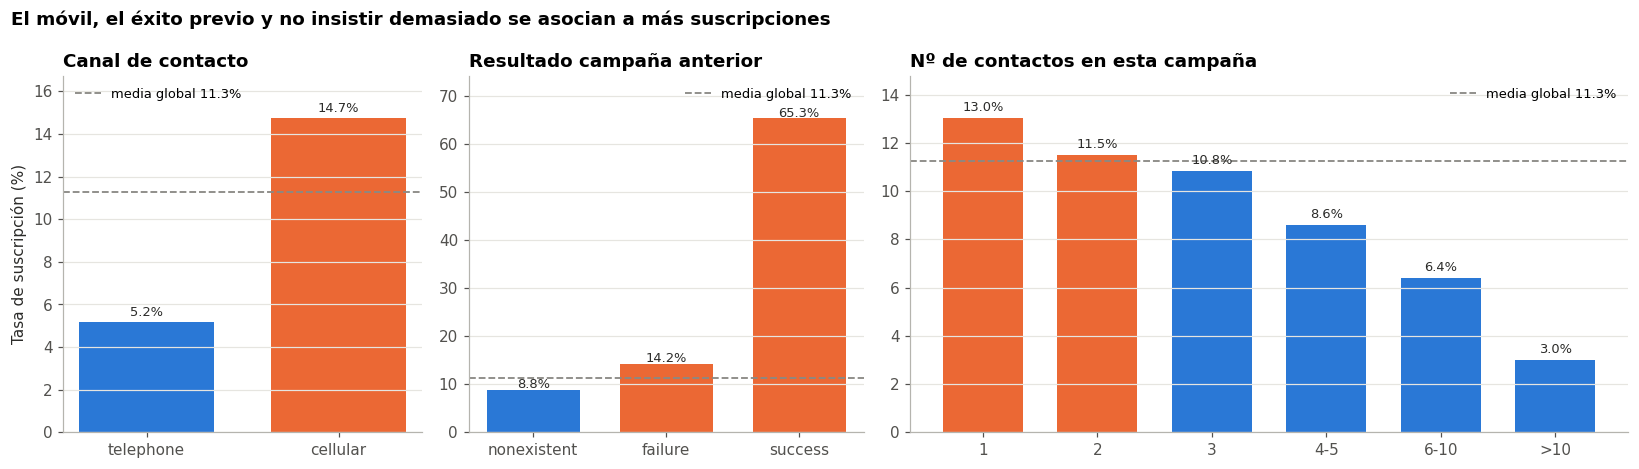

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), gridspec_kw={"width_ratios": [1, 1.1, 2]})
fn.barras_conversion(fn.tasa_conversion(df, "contact"), "Canal de contacto", MEDIA, ax=axes[0], horizontal=False)
fn.barras_conversion(fn.tasa_conversion(df, "poutcome"), "Resultado campaña anterior", MEDIA, ax=axes[1], horizontal=False)
fn.barras_conversion(fn.tasa_conversion(df, "grupo_campaign"), "Nº de contactos en esta campaña", MEDIA, ax=axes[2],
                     horizontal=False, ordenar=False)
for ax in axes[1:]:
    ax.set_ylabel("")
fig.suptitle("El móvil, el éxito previo y no insistir demasiado se asocian a más suscripciones", fontweight="bold", x=0.01, ha="left")
fig.tight_layout(); fn.guardar(fig, "05_estrategia_contacto"); plt.show()

In [15]:
fn.tasa_conversion(df, "previous")

,contactos,suscripciones,tasa
previous,,,
0,37103,3271,8.82
1,4778,1008,21.10
2,786,366,46.56
3,232,140,60.34
4,75,41,54.67
5,20,15,75.00
6,5,3,60.00
7,1,0,0.00


**Hallazgos de la estrategia de contacto:**
- **Canal**: el **móvil (14,7 %)** casi triplica al teléfono fijo (5,2 %).
- **Historial**: si la campaña anterior fue un **éxito, el 65 %** vuelve a suscribir (×5,8 la media). Los clientes contactados antes de esta campaña (`contactado_antes = 1`) convierten un 64 % frente al 9 % de los nuevos.
- **Insistencia**: la tasa **cae de forma monótona** con el nº de llamadas: 13 % con 1 contacto, 6,4 % con 6-10 y **3 % con más de 10**. A partir del 3.er-4.º intento, insistir rinde muy poco.
- El efecto del canal se mantiene aunque se controle por el historial:

In [16]:
pd.pivot_table(df, index="poutcome", columns="contact", values="y_num", aggfunc="mean", observed=True).mul(100).round(1)

contact,cellular,telephone
poutcome,,
failure,14.5,11.3
nonexistent,11.7,4.6
success,65.4,64.2


Entre clientes sin historial (`nonexistent`), el móvil convierte un 11,7 % y el fijo un 4,6 %.

## 5. Duración de la llamada

> ⚠️ `duration` **solo se conoce cuando la llamada ha terminado**, así que no sirve para decidir a quién llamar. Es útil para entender el proceso, pero no debe usarse como variable predictiva antes del contacto.

In [17]:
df["tramo_duracion"] = pd.cut(df["duration"], bins=[-1, 60, 120, 180, 300, 600, 1000, np.inf],
                              labels=["<1 min", "1-2", "2-3", "3-5", "5-10", "10-17", ">17 min"])
tabla_dur = fn.tasa_conversion(df, "tramo_duracion")
tabla_dur

,contactos,suscripciones,tasa
tramo_duracion,,,
<1 min,4467,0,0.00
1-2,9031,173,1.92
2-3,8147,416,5.11
3-5,9695,998,10.29
5-10,8066,1507,18.68
10-17,2607,1166,44.73
>17 min,987,584,59.17


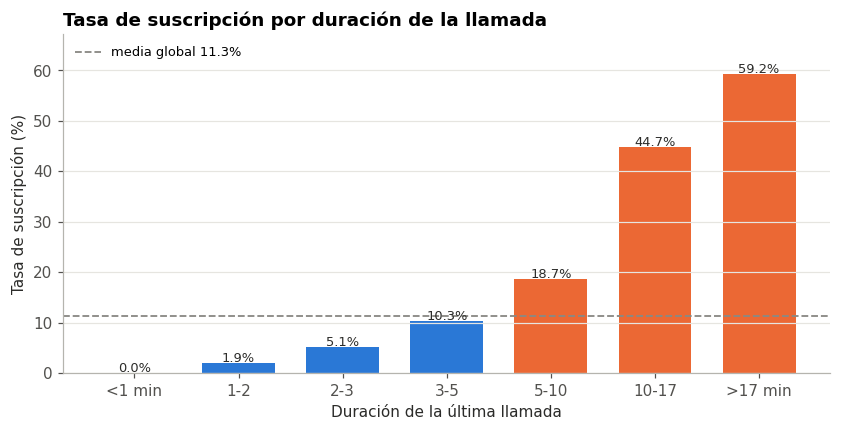

In [18]:
fig, ax = plt.subplots(figsize=(9, 4))
fn.barras_conversion(tabla_dur, "Tasa de suscripción por duración de la llamada", MEDIA, ax=ax, horizontal=False, ordenar=False)
ax.set_xlabel("Duración de la última llamada")
fn.guardar(fig, "06_conversion_duracion"); plt.show()

Relación muy fuerte y creciente: **ninguna llamada de menos de 1 minuto** acabó en suscripción, mientras que las de **más de 10 minutos convierten un 45-59 %**. Es la variable con mayor correlación con `y` (r = 0,41), pero es consecuencia del interés del cliente más que causa.

## 6. Contexto macroeconómico y correlaciones

In [19]:
cols_corr = ["y_num", "age", "duration", "campaign", "previous", "contactado_antes",
             "emp_var_rate", "cons_price_idx", "cons_conf_idx", "euribor3m", "nr_employed",
             "income", "num_web_visits_month", "hijos_total"]
corr = df[cols_corr].corr()
corr["y_num"].drop("y_num").sort_values(key=abs, ascending=False).round(3).to_frame("correlación con y")

,correlación con y
duration,0.405
nr_employed,-0.356
contactado_antes,0.327
euribor3m,-0.309
emp_var_rate,-0.298
previous,0.233
cons_price_idx,-0.136
campaign,-0.066
cons_conf_idx,0.057
age,0.031


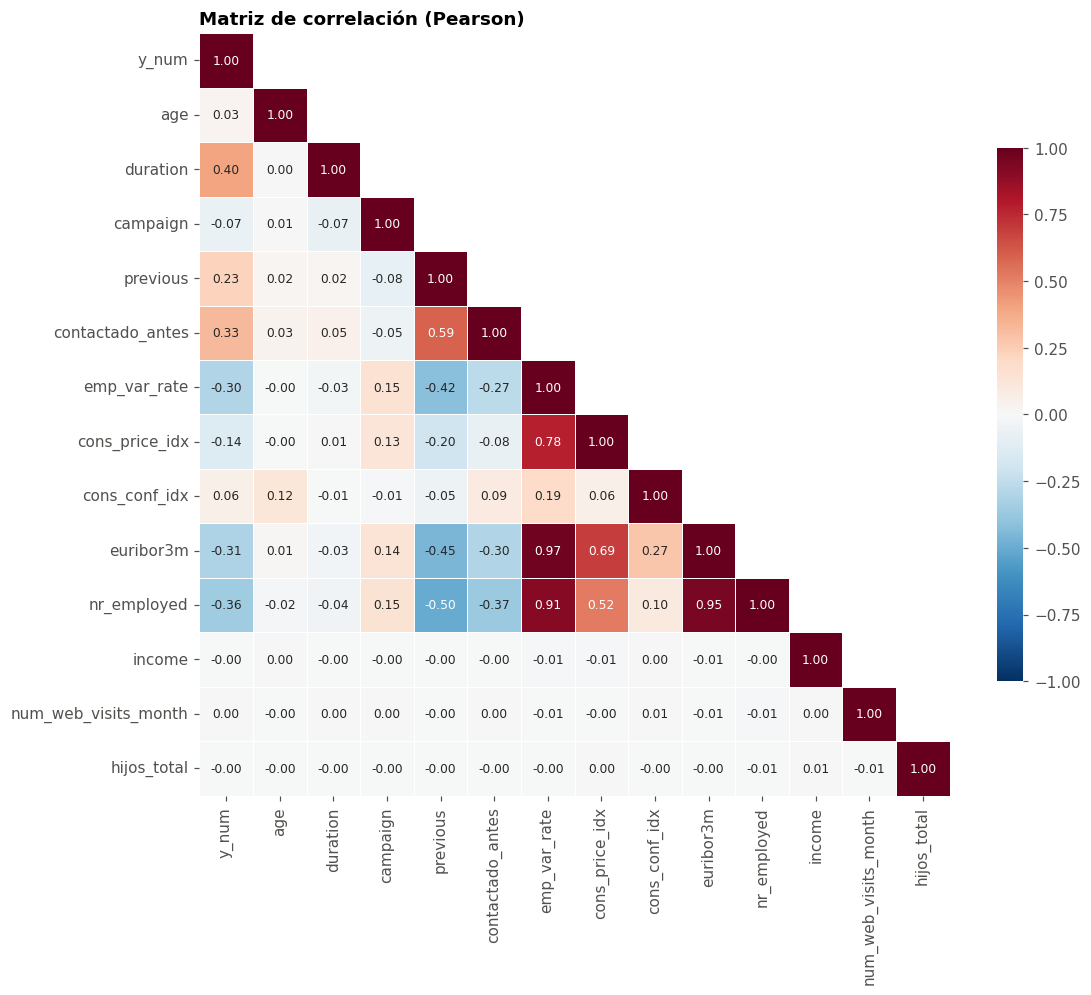

In [20]:
fig, ax = plt.subplots(figsize=(11, 9))
mascara = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mascara, cmap="RdBu_r", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"size": 8}, linewidths=0.5, linecolor="white", cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Matriz de correlación (Pearson)")
ax.grid(False)
fn.guardar(fig, "07_matriz_correlacion"); plt.show()

**Lectura de la matriz:**
- Los indicadores macro están **fuertemente correlacionados entre sí** (`euribor3m`–`emp_var_rate` 0,97; `euribor3m`–`nr_employed` 0,95): describen el mismo ciclo económico.
- Todos ellos se correlacionan **negativamente** con la suscripción (`nr_employed` −0,36, `euribor3m` −0,31, `emp_var_rate` −0,30).
- `income`, `num_web_visits_month` y `hijos_total` tienen correlación **≈ 0** con todo: no aportan información sobre el resultado.

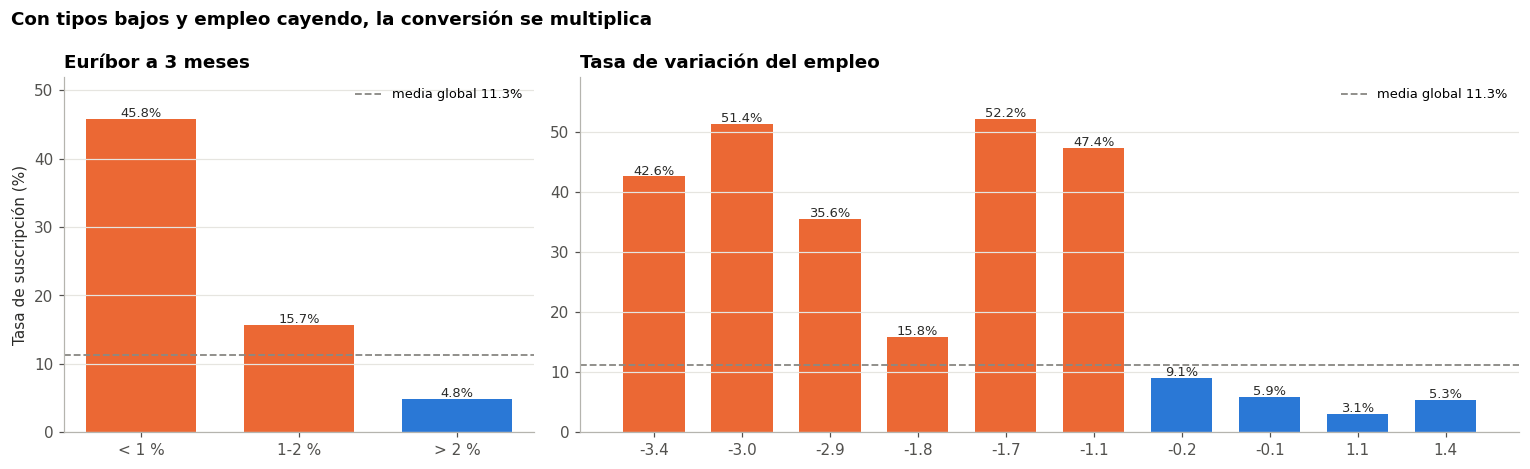

In [21]:
df["tramo_euribor"] = pd.cut(df["euribor3m"], bins=[0, 1, 2, 6], labels=["< 1 %", "1-2 %", "> 2 %"])
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3), gridspec_kw={"width_ratios": [1, 2]})
fn.barras_conversion(fn.tasa_conversion(df, "tramo_euribor"), "Euríbor a 3 meses", MEDIA, ax=axes[0],
                     horizontal=False, ordenar=False)
fn.barras_conversion(fn.tasa_conversion(df, "emp_var_rate"), "Tasa de variación del empleo", MEDIA, ax=axes[1],
                     horizontal=False, ordenar=False)
axes[1].set_ylabel("")
fig.suptitle("Con tipos bajos y empleo cayendo, la conversión se multiplica", fontweight="bold", x=0.01, ha="left")
fig.tight_layout(); fn.guardar(fig, "08_contexto_macro"); plt.show()

In [22]:
fn.tasa_conversion(df, "tramo_euribor")

,contactos,suscripciones,tasa
tramo_euribor,,,
< 1 %,4121,1889,45.84
1-2 %,10038,1571,15.65
> 2 %,28841,1384,4.80


El contexto económico es uno de los factores más potentes: con el **euríbor por debajo del 1 % convierte el 46 %** de los contactos; con el euríbor por encima del 2 %, **solo el 4,8 %**. Cuando el empleo cae con fuerza (`emp_var_rate` ≤ −1,7) la tasa supera el 35-50 %.

Interpretación: en un entorno de **crisis y tipos bajos** (2009-2010 en el dataset original), los clientes buscan productos seguros como el depósito a plazo. Además, en esas etapas el banco hizo **menos llamadas pero más dirigidas** (más móvil, más clientes con historial).

In [23]:
# Volumen de contactos vs. conversión en cada contexto: menos llamadas, más eficaces
fn.tasa_conversion(df, "tramo_euribor").assign(
    pct_movil=df.groupby("tramo_euribor", observed=True)["contact"].apply(lambda s: (s == "cellular").mean() * 100).round(1),
    pct_con_historial=df.groupby("tramo_euribor", observed=True)["contactado_antes"].mean().mul(100).round(1),
)

,contactos,suscripciones,tasa,pct_movil,pct_con_historial
tramo_euribor,,,,,
< 1 %,4121,1889,45.84,84.8,27.8
1-2 %,10038,1571,15.65,92.4,4.1
> 2 %,28841,1384,4.80,50.7,0.1


### ¿Y la fecha del contacto?

Como se vio en el notebook 01, la columna `date` no es coherente con los indicadores macro. Lo confirma que la conversión es **plana** por año y por mes:

In [24]:
pd.concat({"año": fn.tasa_conversion(df, "contact_year")["tasa"],
           "mes": fn.tasa_conversion(df, "contact_month")["tasa"]}).to_frame("tasa %").T

año                               mes                                                                             
         2015   2016   2017   2018   2019  1      2      3      4      5      6      7      8      9      10     11     12  
tasa %  10.87  11.68  10.97  11.45  11.29  11.6  11.13  10.73  11.19  10.63  11.33  11.41  11.46  10.25  12.36  11.49  11.45

Entre 10,3 % y 12,4 % en todos los casos (ruido alrededor de la media). La estacionalidad **no puede analizarse** con esta columna; el momento real de la campaña lo reflejan los indicadores macro.

## 7. Datos de cliente del Excel

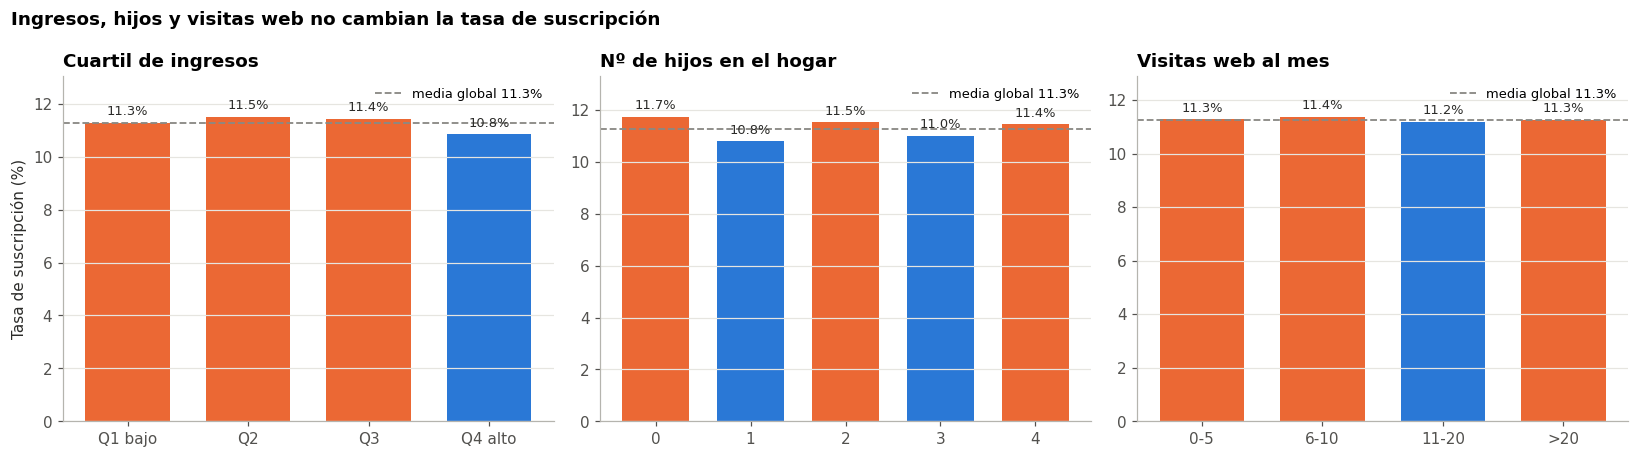

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
vars_excel = {"grupo_ingresos": "Cuartil de ingresos", "hijos_total": "Nº de hijos en el hogar", "grupo_web": "Visitas web al mes"}
for ax, (col, titulo) in zip(axes, vars_excel.items()):
    fn.barras_conversion(fn.tasa_conversion(df, col), titulo, MEDIA, ax=ax, horizontal=False, ordenar=False)
for ax in axes[1:]:
    ax.set_ylabel("")
fig.suptitle("Ingresos, hijos y visitas web no cambian la tasa de suscripción", fontweight="bold", x=0.01, ha="left")
fig.tight_layout(); fn.guardar(fig, "09_variables_excel"); plt.show()

In [26]:
# Los ingresos tampoco varían con la profesión (algo poco realista)
df.groupby("job", observed=True)["income"].agg(["median", "mean", "std"]).round(0).sort_values("median")

,median,mean,std
job,,,
services,91844.0,92272.0,50579.0
blue-collar,92304.0,92633.0,50346.0
retired,92456.0,92684.0,50046.0
admin,93040.0,93285.0,50595.0
student,93449.0,93548.0,50930.0
technician,93605.0,93653.0,50711.0
self-employed,93776.0,93805.0,51159.0
management,93998.0,93513.0,49864.0
entrepreneur,94090.0,93581.0,50253.0


Ingresos, hijos y visitas web dan tasas entre 10,8 % y 11,7 %, es decir, **iguales a la media**. Además, los ingresos medianos son prácticamente iguales en todas las profesiones (~92-97 mil), incluso en estudiantes y desempleados, y siguen una distribución uniforme. Todo indica que **estas variables son sintéticas / aleatorias** y no reflejan el comportamiento real de los clientes. Es un hallazgo en sí mismo: no conviene tomar decisiones comerciales basadas en ellas.

### El año de alta: un ejemplo de variable de confusión

In [27]:
fn.tasa_conversion(df, "anio_alta")

,contactos,suscripciones,tasa
anio_alta,,,
2012,20018,918,4.59
2013,8918,690,7.74
2014,14064,3236,23.01


A primera vista, los clientes dados de alta en **2014 convierten un 23 %**, frente al 4,6 % de los de 2012. Pero hay que comprobar si el año de alta está mezclado con el contexto económico:

In [28]:
pd.crosstab(df["anio_alta"], df["tramo_euribor"], normalize="index").mul(100).round(1)

tramo_euribor,< 1 %,1-2 %,> 2 %
anio_alta,,,
2012,0.0,0.0,100.0
2013,0.0,15.6,84.4
2014,29.3,61.5,9.2


In [29]:
tabla_conf = pd.pivot_table(df, index="tramo_euribor", columns="anio_alta", values="y_num", aggfunc="mean", observed=True).mul(100).round(1)
n_conf = pd.pivot_table(df, index="tramo_euribor", columns="anio_alta", values="y_num", aggfunc="count", observed=True)
tabla_conf.where(n_conf >= 100)  # se ocultan celdas con < 100 clientes

anio_alta,2012,2013,2014
tramo_euribor,,,
< 1 %,NaN,NaN,45.8
1-2 %,NaN,20.6,14.9
> 2 %,4.6,5.4,4.8


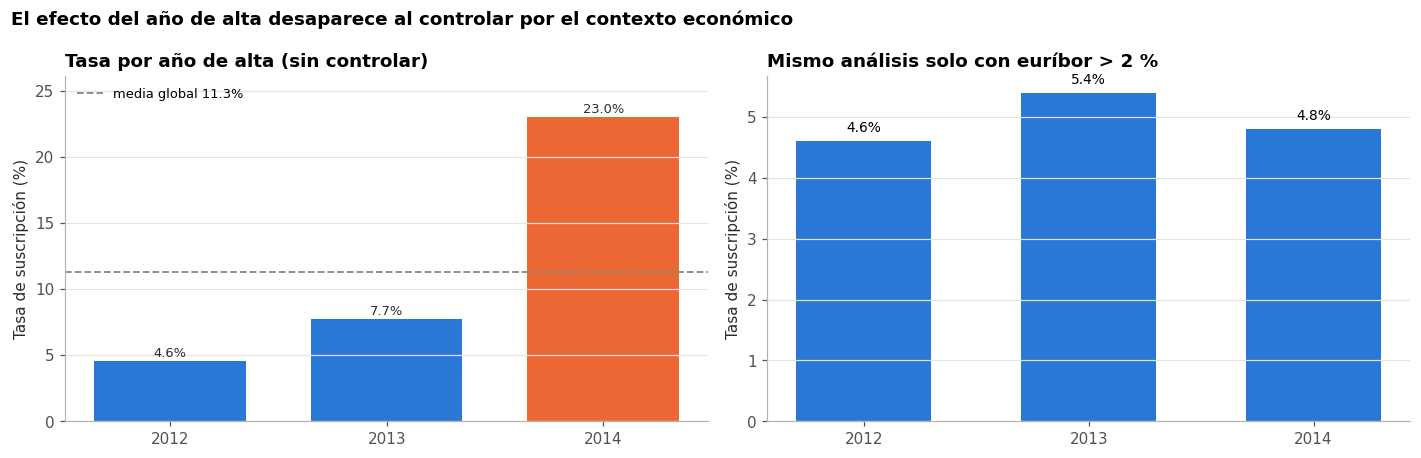

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
fn.barras_conversion(fn.tasa_conversion(df, "anio_alta"), "Tasa por año de alta (sin controlar)", MEDIA, ax=axes[0],
                     horizontal=False, ordenar=False)
datos = tabla_conf.where(n_conf >= 100).loc["> 2 %"].dropna()
axes[1].bar(datos.index.astype(str), datos.values, color=fn.COLOR_PRINCIPAL, width=0.6)
for i, v in enumerate(datos.values):
    axes[1].text(i, v + 0.15, f"{v:.1f}%", ha="center", fontsize=9)
axes[1].set_title("Mismo análisis solo con euríbor > 2 %"); axes[1].set_ylabel("Tasa de suscripción (%)")
fig.suptitle("El efecto del año de alta desaparece al controlar por el contexto económico", fontweight="bold", x=0.01, ha="left")
fig.tight_layout(); fn.guardar(fig, "10_confusion_anio_alta"); plt.show()

El **100 % de los clientes de 2012** (y el 84 % de los de 2013) fueron contactados con el euríbor por encima del 2 %, mientras que el 91 % de los de 2014 lo fueron con tipos por debajo del 2 %. **Dentro de un mismo contexto** (euríbor > 2 %), los tres años convierten prácticamente igual (4,6 %, 5,4 % y 4,8 %). La diferencia aparente se debe al **contexto económico**, no a la antigüedad del cliente.

## 8. Cruces de variables

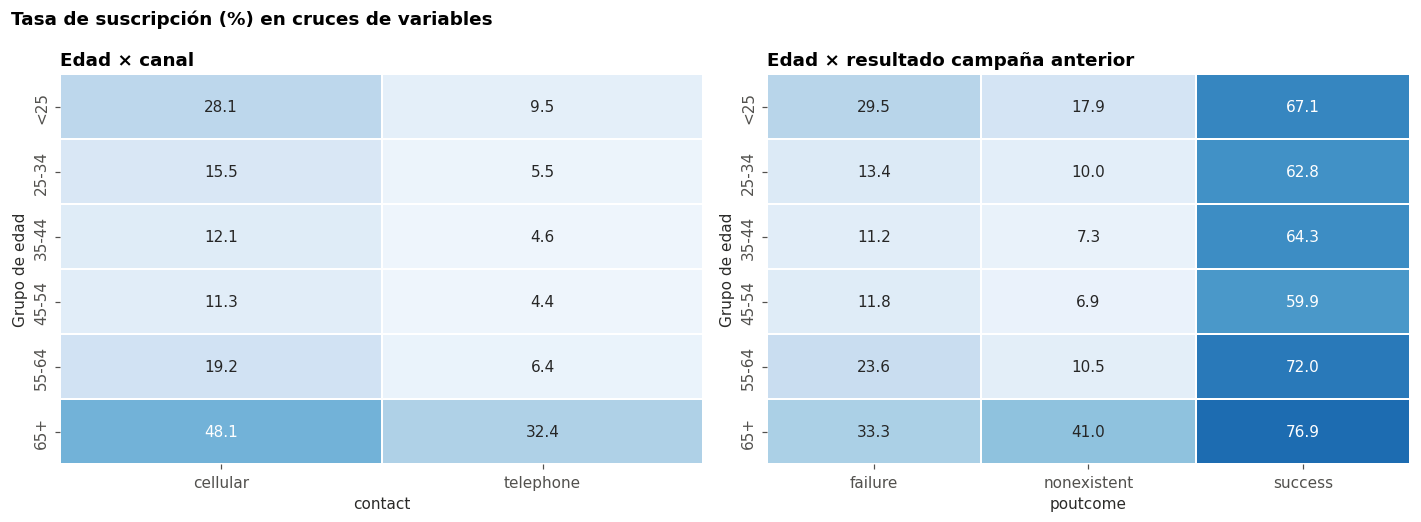

In [31]:
pivot_edad_canal = pd.pivot_table(df, index="grupo_edad", columns="contact", values="y_num", aggfunc="mean", observed=True).mul(100)
pivot_edad_hist = pd.pivot_table(df, index="grupo_edad", columns="poutcome", values="y_num", aggfunc="mean", observed=True).mul(100)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, tabla, titulo in zip(axes, [pivot_edad_canal, pivot_edad_hist],
                             ["Edad × canal", "Edad × resultado campaña anterior"]):
    sns.heatmap(tabla, annot=True, fmt=".1f", cmap="Blues", cbar=False, linewidths=1, linecolor="white", ax=ax,
                vmin=0, vmax=100)
    ax.set_title(titulo); ax.set_ylabel("Grupo de edad"); ax.grid(False)
fig.suptitle("Tasa de suscripción (%) en cruces de variables", fontweight="bold", x=0.01, ha="left")
fig.tight_layout(); fn.guardar(fig, "11_cruces_edad"); plt.show()

- Los **mayores de 65** convierten un **48 % por móvil** e incluso un **32 % por fijo**, muy por encima de cualquier otro grupo.
- Un **éxito previo** dispara la conversión en **todas** las edades (60-77 %).
- El patrón en U de la edad se mantiene dentro de cada canal: no es solo un efecto del canal.

In [32]:
# Segmentos concretos de mayor y menor conversión (con al menos 200 contactos)
segmentos = fn.tasa_conversion(df, ["grupo_edad", "contact", "poutcome"], min_n=200).sort_values("tasa")
pd.concat({"menor conversión": segmentos.head(5), "mayor conversión": segmentos.tail(5)})

contactos  suscripciones   tasa
                 grupo_edad contact   poutcome                                    
menor conversión 45-54      telephone nonexistent       3054            120   3.93
                 35-44      telephone nonexistent       6602            285   4.32
                 25-34      telephone nonexistent       4063            200   4.92
                 55-64      telephone nonexistent       1199             68   5.67
                 <25        telephone nonexistent        210             13   6.19
mayor conversión <25        cellular  nonexistent        546            122  22.34
                 55-64      cellular  failure            307             73  23.78
                 65+        cellular  nonexistent        299            129  43.14
                 25-34      cellular  success            407            256  62.90
                 35-44      cellular  success            398            258  64.82

## 9. Ranking de factores

Para ordenar qué variables categóricas están más asociadas a la suscripción se usa el **test chi-cuadrado** (¿la asociación es significativa?) y la **V de Cramér** (¿cómo de fuerte es? 0 = nada, 1 = total).

In [33]:
vars_test = ["tramo_duracion", "tramo_euribor", "poutcome", "contactado_antes", "contact", "grupo_edad", "job",
             "grupo_campaign", "anio_alta", "education", "marital", "housing", "loan",
             "grupo_ingresos", "hijos_total", "grupo_web", "contact_month"]
ranking = fn.asociacion_categoricas(df, vars_test)
ranking["significativa (p<0.05)"] = ranking["p_valor"] < 0.05
ranking

,chi2,p_valor,v_cramer,significativa (p<0.05)
variable,,,,
tramo_duracion,7305.0,0.000000e+00,0.412,True
tramo_euribor,6327.4,0.000000e+00,0.384,True
contactado_antes,4589.3,0.000000e+00,0.327,True
poutcome,4459.6,0.000000e+00,0.322,True
anio_alta,2944.9,0.000000e+00,0.262,True
grupo_edad,1093.4,3.572177e-234,0.159,True
job,999.9,1.992658e-207,0.152,True
contact,912.6,1.807802e-200,0.146,True
grupo_campaign,214.1,2.748728e-44,0.071,True


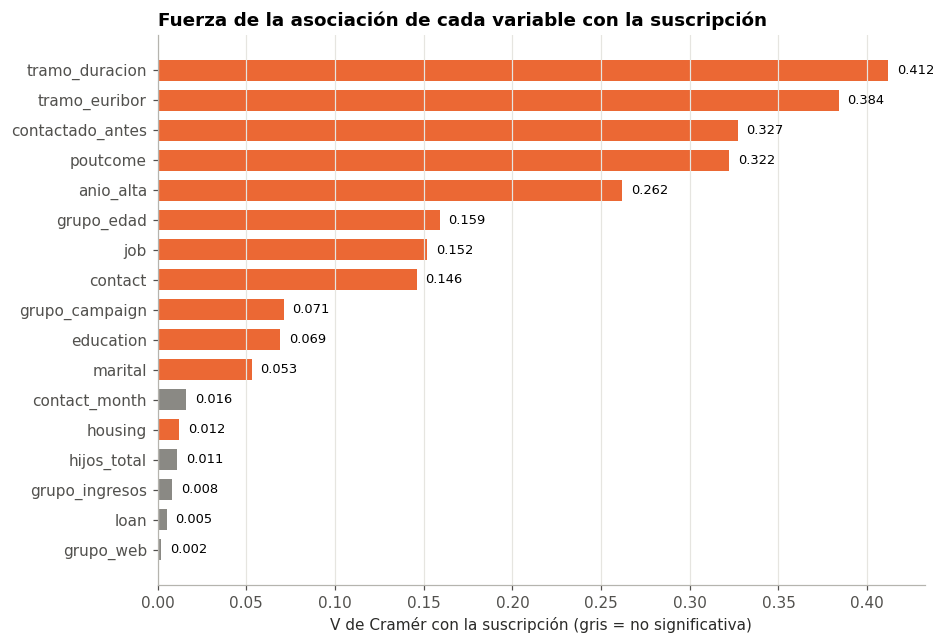

In [34]:
fig, ax = plt.subplots(figsize=(9, 6.5))
datos = ranking["v_cramer"].sort_values()
colores = [fn.COLOR_SECUNDARIO if s else fn.COLOR_NEUTRO for s in ranking.loc[datos.index, "significativa (p<0.05)"]]
ax.barh(datos.index, datos.values, color=colores, height=0.7)
for i, v in enumerate(datos.values):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=8.5)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_xlabel("V de Cramér con la suscripción (gris = no significativa)")
ax.set_title("Fuerza de la asociación de cada variable con la suscripción")
fn.guardar(fig, "12_ranking_factores"); plt.show()

El ranking confirma el análisis visual. Por orden:
1. **Duración de la llamada** (no accionable a priori).
2. **Contexto macroeconómico** (euríbor).
3. **Historial con el cliente** (`poutcome`, `contactado_antes`).
4. **Edad / profesión** y **canal**.
5. Nº de contactos, educación, estado civil (efecto pequeño).
6. **Asociación nula o despreciable** (V < 0,02): vivienda, préstamos, ingresos, hijos, visitas web y mes de contacto. `housing` sale estadísticamente significativa solo por el gran tamaño muestral; su efecto es irrelevante (10,9 % vs 11,6 %).

(El año de alta aparece alto, pero ya se ha visto que es un efecto de confusión con el contexto económico.)

## 10. Conclusiones

1. **Conversión baja (11,3 %)** → cada punto de mejora en la segmentación tiene mucho impacto.
2. **El contexto económico manda**: con euríbor < 1 % convierte el 46 % vs el 4,8 % con euríbor > 2 %. El depósito se vende mucho mejor en entornos de tipos bajos e incertidumbre laboral.
3. **El historial es el mejor predictor accionable**: un éxito previo da un 65 % de conversión.
4. **Edad en U**: <25 (24 %) y ≥65 (46 %) son los segmentos más receptivos; estudiantes y jubilados lideran por profesión.
5. **El móvil triplica al fijo** (14,7 % vs 5,2 %), también entre clientes sin historial.
6. **Insistir no compensa**: a partir de 3-4 llamadas la tasa cae por debajo del 9 % y con >10 llamadas, al 3 %.
7. **Llamadas largas = interés**: >10 min convierten ~50 %, pero la duración solo se conoce después.
8. **Datos del Excel poco informativos**: ingresos, hijos y visitas web no se asocian a la suscripción; el año de alta es una variable de confusión.
9. **Calidad del dato**: la fecha y las coordenadas no son fiables; conviene revisarlas en origen.

Las recomendaciones de negocio se detallan en el `README.md`.